# Tarea
Visualiza la red de pases exitosos de los jugadores del Real Madrid, mostrando las conexiones de pases y las posiciones promedio de los jugadores en un campo de fútbol con fondo negro y líneas blancas. Los nodos deben representar la posición promedio de cada jugador, dimensionados según sus pases exitosos totales y coloreados a juego con el fondo, con un borde rojo. Las líneas de pase deben ser rojas, con un grosor variable según el número de pases.

In [ ]:
!pip install mplsoccer
!pip install cmasher
!pip install highlight_text

## Filtrar Pases Exitosos del Real Madrid

Importamos librerías, cargamos el documento csv del partido elegido y creamos un DataFrame con los pases exitosos del Real Madrid para su posterior análisis y visualización de la red de pases.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch

df = pd.read_csv('/content/pass_data_Real Madrid_Leganés.csv', encoding='latin1')
print("DataFrame loaded successfully. Displaying the first 5 rows:")
df.head()

DataFrame loaded successfully. Displaying the first 5 rows:


,team,player,period,min,sec,pass zone,x,y,x_end,y_end,pass length,pass angle,outcome
0,Real Madrid,Karim Benzema,1,0,1,Back,50.4,49.7,37.6,59.2,14.9,2.7,1
1,Real Madrid,Toni Kroos,1,0,2,Back,38.9,57.1,38.0,45.8,7.7,4.6,1
2,Real Madrid,Luka Modric,1,0,5,Back,32.9,36.9,30.4,53.0,11.3,1.8,1
3,Real Madrid,Casemiro,1,0,6,Back,30.4,53.0,20.7,37.1,14.9,4.0,1
4,Real Madrid,Raphael Varane,1,0,7,Back,20.7,37.1,22.2,7.1,20.5,4.8,1


In [ ]:
real_madrid_successful_passes = df[(df['team'] == 'Real Madrid') & (df['outcome'] == 1)]

print("DataFrame 'real_madrid_successful_passes' created successfully. Displaying the first 5 rows:")
print(real_madrid_successful_passes.head())
print(f"\nTotal successful passes for Real Madrid: {len(real_madrid_successful_passes)}")

DataFrame 'real_madrid_successful_passes' created successfully. Displaying the first 5 rows:
          team          player  period  min  sec pass zone     x     y  x_end  \
0  Real Madrid   Karim Benzema       1    0    1      Back  50.4  49.7   37.6   
1  Real Madrid      Toni Kroos       1    0    2      Back  38.9  57.1   38.0   
2  Real Madrid     Luka Modric       1    0    5      Back  32.9  36.9   30.4   
3  Real Madrid        Casemiro       1    0    6      Back  30.4  53.0   20.7   
4  Real Madrid  Raphael Varane       1    0    7      Back  20.7  37.1   22.2   

   y_end  pass length  pass angle  outcome  
0   59.2         14.9         2.7        1  
1   45.8          7.7         4.6        1  
2   53.0         11.3         1.8        1  
3   37.1         14.9         4.0        1  
4    7.1         20.5         4.8        1  

Total successful passes for Real Madrid: 830


## Calcular Posiciones Promedio de Jugadores

Determinamos la posición promedio en el campo de cada jugador del Real Madrid a partir de sus pases exitosos, lo que servirá como base para los nodos de la red.

Para determinar la posición media de cada jugador, agruparé el DataFrame 'real_madrid_successful_passes' por 'jugador' y calcularé la media de sus coordenadas 'x' e 'y'.

In [ ]:
real_madrid_player_positions = real_madrid_successful_passes.groupby('player')[['x', 'y']].mean().reset_index()

print("Average positions for Real Madrid players:")
print(real_madrid_player_positions.head())

Average positions for Real Madrid players:
            player          x          y
0         Casemiro  45.325676  41.818919
1    Dani Ceballos  58.592593  48.262963
2  Daniel Carvajal  50.626531  10.900000
3      Gareth Bale  61.052941  30.427451
4             Isco  55.278378  52.040541


## Inferir Receptores y Contar Conexiones de Pases

Identificar los receptores de cada pase exitoso y contar el número de pases exitosos entre cada par de jugadores, formando la base de las aristas de la red.


La primera instrucción es ordenar el DataFrame `real_madrid_successful_passes` cronológicamente por periodo, minutos y segundos. Esto es crucial para identificar correctamente a los receptores de los pases.

In [ ]:
real_madrid_successful_passes_sorted = real_madrid_successful_passes.sort_values(by=['period', 'min', 'sec']).reset_index(drop=True)

print("DataFrame 'real_madrid_successful_passes' sorted chronologically.")
print(real_madrid_successful_passes_sorted.head())

DataFrame 'real_madrid_successful_passes' sorted chronologically.
          team          player  period  min  sec pass zone     x     y  x_end  \
0  Real Madrid   Karim Benzema       1    0    1      Back  50.4  49.7   37.6   
1  Real Madrid      Toni Kroos       1    0    2      Back  38.9  57.1   38.0   
2  Real Madrid     Luka Modric       1    0    5      Back  32.9  36.9   30.4   
3  Real Madrid        Casemiro       1    0    6      Back  30.4  53.0   20.7   
4  Real Madrid  Raphael Varane       1    0    7      Back  20.7  37.1   22.2   

   y_end  pass length  pass angle  outcome  
0   59.2         14.9         2.7        1  
1   45.8          7.7         4.6        1  
2   53.0         11.3         1.8        1  
3   37.1         14.9         4.0        1  
4    7.1         20.5         4.8        1  


Para identificar a los receptores de pases, crearé una columna de "receptor" desplazando la columna de "jugador" y asegurándome de que el pase se realice dentro del mismo equipo y periodo. Después, filtraré los autopase y los receptores NaN, y finalmente, agruparé los datos para contabilizar los pases exitosos entre jugadores.

In [ ]:
real_madrid_successful_passes_sorted['recipient'] = real_madrid_successful_passes_sorted['player'].shift(-1)
real_madrid_successful_passes_sorted['next_team'] = real_madrid_successful_passes_sorted['team'].shift(-1)
real_madrid_successful_passes_sorted['next_period'] = real_madrid_successful_passes_sorted['period'].shift(-1)

# Solo asigna un destinatario si el siguiente pase es del mismo equipo y en el mismo período
real_madrid_successful_passes_sorted.loc[
    (real_madrid_successful_passes_sorted['team'] != real_madrid_successful_passes_sorted['next_team']) |
    (real_madrid_successful_passes_sorted['period'] != real_madrid_successful_passes_sorted['next_period']),
    'recipient'
] = None

# Filtrar los pases propios y las filas donde el destinatario es NaN
real_madrid_pass_connections_data = real_madrid_successful_passes_sorted[
    (real_madrid_successful_passes_sorted['player'] != real_madrid_successful_passes_sorted['recipient']) &
    real_madrid_successful_passes_sorted['recipient'].notna()
].copy()


# Agrupar por jugador (pasador) y receptor para contar pases exitosos
real_madrid_pass_connections = real_madrid_pass_connections_data.groupby(['player', 'recipient']).size().reset_index(name='num_passes')
real_madrid_pass_connections = real_madrid_pass_connections.rename(columns={'player': 'passer'})

print("Real Madrid pass connections created:")
print(real_madrid_pass_connections.head())
print(f"\nTotal unique pass connections for Real Madrid: {len(real_madrid_pass_connections)}")

Real Madrid pass connections created:
     passer        recipient  num_passes
0  Casemiro    Dani Ceballos           5
1  Casemiro  Daniel Carvajal           4
2  Casemiro      Gareth Bale           4
3  Casemiro             Isco           4
4  Casemiro    Karim Benzema           2

Total unique pass connections for Real Madrid: 145


## Unir Conexiones de Pases con Coordenadas

Integrar las coordenadas de inicio y fin de cada pase a los datos de conexiones para que puedan ser dibujadas en el campo de fútbol.


In [ ]:
pitch_black_background = Pitch(pitch_type='opta', pitch_color='#22312b', line_color='white', stripe=False)

plt.show()

El primer paso es fusionar el DataFrame `real_madrid_pass_connections` con `real_madrid_player_positions` dos veces para obtener las coordenadas de inicio y fin de cada conexión de pase y renombrar las columnas según corresponda para crear `real_madrid_pass_plot_data`.

In [ ]:
real_madrid_pass_plot_data = real_madrid_pass_connections.merge(
    real_madrid_player_positions.rename(columns={'x': 'x_start', 'y': 'y_start'}),
    left_on='passer',
    right_on='player',
    how='left'
).drop('player', axis=1)

real_madrid_pass_plot_data = real_madrid_pass_plot_data.merge(
    real_madrid_player_positions.rename(columns={'x': 'x_end', 'y': 'y_end'}),
    left_on='recipient',
    right_on='player',
    how='left'
).drop('player', axis=1)

print("DataFrame 'real_madrid_pass_plot_data' created successfully. Displaying the first 5 rows:")
print(real_madrid_pass_plot_data.head())

DataFrame 'real_madrid_pass_plot_data' created successfully. Displaying the first 5 rows:
     passer        recipient  num_passes    x_start    y_start      x_end  \
0  Casemiro    Dani Ceballos           5  45.325676  41.818919  58.592593   
1  Casemiro  Daniel Carvajal           4  45.325676  41.818919  50.626531   
2  Casemiro      Gareth Bale           4  45.325676  41.818919  61.052941   
3  Casemiro             Isco           4  45.325676  41.818919  55.278378   
4  Casemiro    Karim Benzema           2  45.325676  41.818919  67.672727   

       y_end  
0  48.262963  
1  10.900000  
2  30.427451  
3  52.040541  
4  57.339394  


Ahora que los datos de conexión de pase están preparados, definiré constantes para un tamaño de nodo fijo y una transparencia de línea uniforme, y luego procederé a dibujar el campo y a trazar los nodos de los jugadores y las conexiones de pase como se especifica en las instrucciones para visualizar la red de pase.



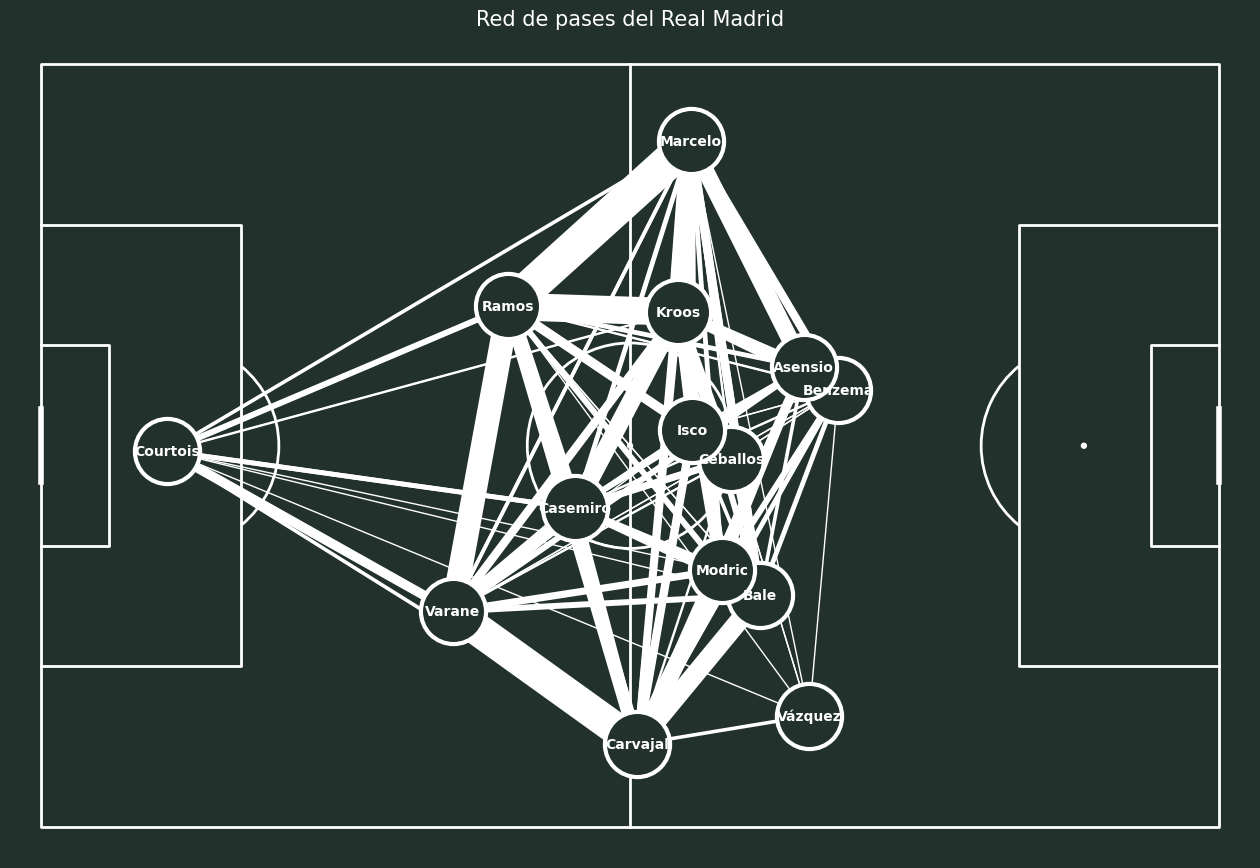

In [ ]:



# Definir constantes para la visualización
FIXED_NODE_SIZE = 2200 #tamaño de los nodos
UNIFORM_LINE_ALPHA = 1.0 # Transparencia uniforme y opaca para las líneas de pase

# Ajustes para el escalado continuo del grosor de línea según las nuevas especificaciones del usuario
MIN_PASS_LINEWIDTH = 1 # Línea muy fina para el mínimo de pases (1 pase)
MAX_PASS_LINEWIDTH = 25 # Línea muy gruesa para el máximo de pases


# Calculate total successful passes per player for initial sizing, though not used for node size in this step
real_madrid_player_total_passes = real_madrid_successful_passes.groupby('player').size().reset_index(name='total_passes')
real_madrid_player_positions_with_data = real_madrid_player_positions.merge(
    real_madrid_player_total_passes, on='player', how='left'
)

# Generar iniciales para cada jugador (no se usan directamente en el annotate, pero se mantienen si fueran necesarias en otro contexto)
real_madrid_player_positions_with_data['initials'] = real_madrid_player_positions_with_data['player'].apply(
    lambda name: ''.join([n[0] for n in name.split()])
)

# Dibuja el tono usando el objeto pitch_black_background preinicializado
# Asegúrate de usar el objeto 'pitch_black_background' previamente definido y no reinicializar Pitch
fig, ax = pitch_black_background.draw(figsize=(16, 11), constrained_layout=True, tight_layout=False)
fig.set_facecolor('#22312b') # Ensure the figure background around the pitch matches the pitch color

# Nodos de la trama (posiciones promedio de los jugadores e iniciales) con tamaño fijo
for index, row in real_madrid_player_positions_with_data.iterrows():
 # Círculos de jugadores: interior transparente (coincide con el fondo del campo), borde blanco
    pitch_black_background.scatter(
        row['x'], row['y'],
        ax=ax, s=FIXED_NODE_SIZE, # Tamaño fijo para todos los nodos
        color='#22312b', # El color interior coincide con el fondo del tono para lograr un efecto "transparente"
        edgecolors='white', linewidth=3, alpha=1, zorder=2
    )
    # Player names: white color (display last name if multiple words, else full name)
    player_name_to_display = row['player']
    if ' ' in player_name_to_display:
        player_name_to_display = player_name_to_display.split(' ')[-1]

    pitch_black_background.annotate(
        player_name_to_display, xy=(row['x'], row['y']),
        c='white', va='center', ha='center', size=10, weight='bold', ax=ax, zorder=3
    )

# Calcular el número máximo de pases para escalar el grosor de línea
max_num_passes_overall = real_madrid_pass_plot_data['num_passes'].max()

# Trazar conexiones de pase como líneas (sin flechas)
for index, row in real_madrid_pass_plot_data.iterrows():
    # Escalar el ancho de línea proporcionalmente al número de pases, asegurando un mínimo y un máximo
    # La fórmula es: MIN + (valor_normalizado * (MAX - MIN))
    # Donde valor_normalizado es (num_pases - min_pases_en_df) / (max_pases_en_df - min_pases_en_df)
    # Para simplificar y dado que num_passes puede ser 1, usamos (num_pases / max_num_pases_overall) * MAX_PASS_LINEWIDTH
    # Y luego aseguramos que no sea menor que MIN_PASS_LINEWIDTH
    current_linewidth = max(MIN_PASS_LINEWIDTH, (row['num_passes'] / max_num_passes_overall) * MAX_PASS_LINEWIDTH)

    pitch_black_background.lines(
        row['x_start'], row['y_start'],
        row['x_end'], row['y_end'] ,
        ax=ax, color='white', #Color de las líneas de pase: blanco
        linewidth=current_linewidth, # El ancho de línea varía según la lógica condicional
        alpha=UNIFORM_LINE_ALPHA, # Alfa uniforme para líneas de paso (totalmente opaco)
        zorder=1
    )

plt.title('Red de pases del Real Madrid', color='white', fontsize=15)
plt.show()


#Visualiza la red de pases exitosos de los jugadores del Leganés

## filter_leganes_successful_passes




In [ ]:
leganes_successful_passes = df[(df['team'] == 'Leganés') & (df['outcome'] == 1)]

print("DataFrame 'leganes_successful_passes' created successfully. Displaying the first 5 rows:")
print(leganes_successful_passes.head())
print(f"\nTotal successful passes for Leganés: {len(leganes_successful_passes)}")

DataFrame 'leganes_successful_passes' created successfully. Displaying the first 5 rows:
       team            player  period  min  sec pass zone     x     y  x_end  \
18  Leganés  Dimitrios Siovas       1    1   22      Back  31.6  86.2   36.9   
24  Leganés     Nabil El Zhar       1    1   36      Left  43.9  92.0   55.6   
25  Leganés    Michael Santos       1    1   36      Back  56.3  80.8   46.0   
50  Leganés     Unai Bustinza       1    3   40    Center  33.9  23.6   75.7   
54  Leganés          Juanfran       1    3   59      Back  51.3   0.0   33.4   

    y_end  pass length  pass angle  outcome  
18   91.2          6.5         0.5        1  
24   81.1         14.3         5.7        1  
25   76.1         11.3         3.4        1  
50   76.7         56.8         0.7        1  
54    6.4         19.6         2.8        1  

Total successful passes for Leganés: 202


Para calcular la posición media de cada jugador del Leganés, agruparé el DataFrame `leganes_successful_passes` por 'jugador' y calcularé la media de sus coordenadas 'x' e 'y'.



In [ ]:
leganes_player_positions = leganes_successful_passes.groupby('player')[['x', 'y']].mean().reset_index()

print("Average positions for Leganés players:")
print(leganes_player_positions.head())

Average positions for Leganés players:
             player          x          y
0       Diego Rolan  70.266667  89.066667
1  Dimitrios Siovas  33.741176  74.264706
2     Gerard Gumbau  44.850000  74.905556
3    Guido Carrillo  54.407692  59.438462
4      Iván Cuéllar  10.092857  54.128571



Para inferir los receptores de los pases del Leganés, primero debo ordenar cronológicamente el DataFrame `leganes_successful_passes` para asociar correctamente los pases con sus receptores posteriores. Esto garantiza el orden correcto de los eventos.



In [ ]:
leganes_successful_passes_sorted = leganes_successful_passes.sort_values(by=['period', 'min', 'sec']).reset_index(drop=True)

print("DataFrame 'leganes_successful_passes' sorted chronologically.")
print(leganes_successful_passes_sorted.head())

DataFrame 'leganes_successful_passes' sorted chronologically.
      team            player  period  min  sec pass zone     x     y  x_end  \
0  Leganés  Dimitrios Siovas       1    1   22      Back  31.6  86.2   36.9   
1  Leganés     Nabil El Zhar       1    1   36      Left  43.9  92.0   55.6   
2  Leganés    Michael Santos       1    1   36      Back  56.3  80.8   46.0   
3  Leganés     Unai Bustinza       1    3   40    Center  33.9  23.6   75.7   
4  Leganés          Juanfran       1    3   59      Back  51.3   0.0   33.4   

   y_end  pass length  pass angle  outcome  
0   91.2          6.5         0.5        1  
1   81.1         14.3         5.7        1  
2   76.1         11.3         3.4        1  
3   76.7         56.8         0.7        1  
4    6.4         19.6         2.8        1  




Para identificar a los receptores de pases, crearé una columna de "receptor" desplazando la columna de "jugador" y me aseguraré de que el pase se realice dentro del mismo equipo y periodo. Después, filtraré los pases propios y los receptores no válidos, y finalmente, agruparé los datos para contabilizar los pases exitosos entre jugadores.



In [ ]:
leganes_successful_passes_sorted['recipient'] = leganes_successful_passes_sorted['player'].shift(-1)
leganes_successful_passes_sorted['next_team'] = leganes_successful_passes_sorted['team'].shift(-1)
leganes_successful_passes_sorted['next_period'] = leganes_successful_passes_sorted['period'].shift(-1)

# Solo asigna un destinatario si el siguiente pase es del mismo equipo y en el mismo período
leganes_successful_passes_sorted.loc[
    (leganes_successful_passes_sorted['team'] != leganes_successful_passes_sorted['next_team']) |
    (leganes_successful_passes_sorted['period'] != leganes_successful_passes_sorted['next_period']),
    'recipient'
] = None

# Filtrar los pases propios y las filas donde el destinatario es NaN
leganes_pass_connections_data = leganes_successful_passes_sorted[
    (leganes_successful_passes_sorted['player'] != leganes_successful_passes_sorted['recipient']) &
    leganes_successful_passes_sorted['recipient'].notna()
].copy()


# Agrupar por jugador (pasador) y receptor para contar pases exitosos
leganes_pass_connections = leganes_pass_connections_data.groupby(['player', 'recipient']).size().reset_index(name='num_passes')
leganes_pass_connections = leganes_pass_connections.rename(columns={'player': 'passer'})

print("Leganés pass connections created:")
print(leganes_pass_connections.head())
print(f"\nTotal unique pass connections for Leganés: {len(leganes_pass_connections)}")

Leganés pass connections created:
             passer       recipient  num_passes
0       Diego Rolan  Jonathan Silva           3
1  Dimitrios Siovas    Iván Cuéllar           1
2  Dimitrios Siovas  Jonathan Silva           2
3  Dimitrios Siovas        Juanfran           1
4  Dimitrios Siovas  Michael Santos           2

Total unique pass connections for Leganés: 96


Para integrar las coordenadas de inicio y fin de cada conexión de pase, fusionaré el DataFrame `leganes_pass_connections` dos veces con `leganes_player_positions`, renombrando las columnas apropiadamente para distinguir entre las coordenadas de inicio y fin.



In [ ]:
leganes_pass_plot_data = leganes_pass_connections.merge(
    leganes_player_positions.rename(columns={'x': 'x_start', 'y': 'y_start'}),
    left_on='passer',
    right_on='player',
    how='left'
).drop('player', axis=1)

leganes_pass_plot_data = leganes_pass_plot_data.merge(
    leganes_player_positions.rename(columns={'x': 'x_end', 'y': 'y_end'}),
    left_on='recipient',
    right_on='player',
    how='left'
).drop('player', axis=1)

print("DataFrame 'leganes_pass_plot_data' created successfully. Displaying the first 5 rows:")
print(leganes_pass_plot_data.head())

DataFrame 'leganes_pass_plot_data' created successfully. Displaying the first 5 rows:
             passer       recipient  num_passes    x_start    y_start  \
0       Diego Rolan  Jonathan Silva           3  70.266667  89.066667   
1  Dimitrios Siovas    Iván Cuéllar           1  33.741176  74.264706   
2  Dimitrios Siovas  Jonathan Silva           2  33.741176  74.264706   
3  Dimitrios Siovas        Juanfran           1  33.741176  74.264706   
4  Dimitrios Siovas  Michael Santos           2  33.741176  74.264706   

       x_end      y_end  
0  54.134783  92.534783  
1  10.092857  54.128571  
2  54.134783  92.534783  
3  41.421053  10.310526  
4  55.983333  73.733333  


Una vez preparados todos los datos necesarios para la red de pases del Leganés, incluyendo pases exitosos, posiciones de los jugadores y conexiones de pases con coordenadas, el paso final es visualizar esta red. Esto implica trazar el campo de fútbol, ​​añadir nodos de jugadores dimensionados según el total de pases exitosos, coloreados en azul con bordes e iniciales blancos, y finalmente dibujar líneas de pase con grosor variable según el número de pases, utilizando líneas blancas para asegurar su visibilidad sobre el fondo



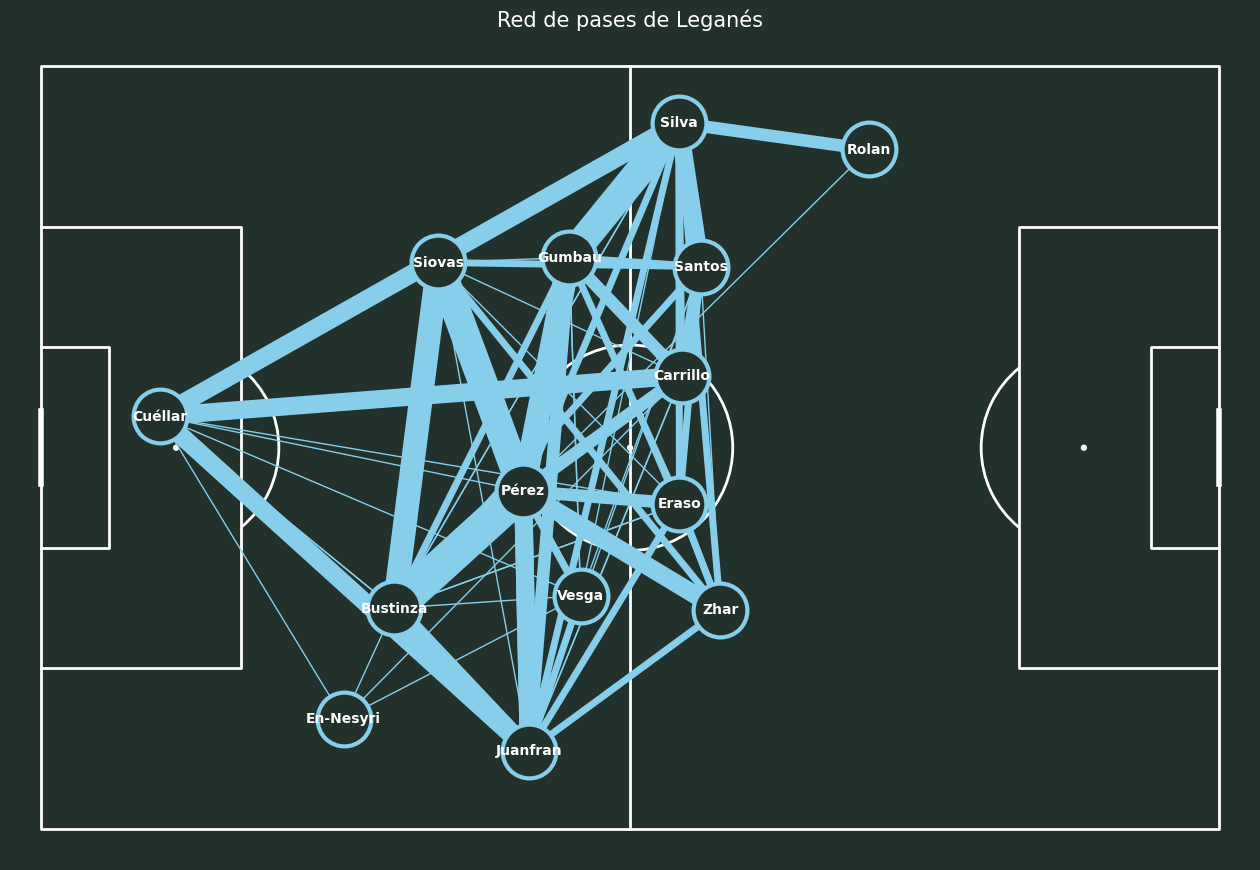

In [ ]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch


FIXED_NODE_SIZE = 1500
UNIFORM_LINE_ALPHA = 1.0

MIN_PASS_LINEWIDTH = 1
MAX_PASS_LINEWIDTH = 25

leganes_player_total_passes = leganes_successful_passes.groupby('player').size().reset_index(name='total_passes')

leganes_player_positions_with_data = leganes_player_positions.merge(
    leganes_player_total_passes, on='player', how='left'
)

leganes_player_positions_with_data['initials'] = leganes_player_positions_with_data['player'].apply(
    lambda name: name.split(' ')[-1] if ' ' in name else name
)

pitch_leganes = Pitch(pitch_type='opta', pitch_color='#22312b', line_color='white', stripe=False)

fig, ax = pitch_leganes.draw(figsize=(16, 11), constrained_layout=True, tight_layout=False)
fig.set_facecolor('#22312b')

for index, row in leganes_player_positions_with_data.iterrows():
    pitch_leganes.scatter(
        row['x'], row['y'],
        ax=ax, s=FIXED_NODE_SIZE,
        color='#22312b',
        edgecolors='skyblue', linewidth=3, alpha=1, zorder=2
    )

    pitch_leganes.annotate(
        row['initials'], xy=(row['x'], row['y']),
        c='white', va='center', ha='center', size=10, weight='bold', ax=ax, zorder=3
    )


max_num_passes_overall = leganes_pass_plot_data['num_passes'].max()
min_num_passes_overall = leganes_pass_plot_data['num_passes'].min()

for index, row in leganes_pass_plot_data.iterrows():
    if max_num_passes_overall == min_num_passes_overall:
        current_linewidth = MIN_PASS_LINEWIDTH
    else:
        normalized_passes = (row['num_passes'] - min_num_passes_overall) / (max_num_passes_overall - min_num_passes_overall)
        current_linewidth = MIN_PASS_LINEWIDTH + normalized_passes * (MAX_PASS_LINEWIDTH - MIN_PASS_LINEWIDTH)

    pitch_leganes.lines(
        row['x_start'], row['y_start'],
        row['x_end'], row['y_end'],
        ax=ax, color='skyblue',
        linewidth=current_linewidth,
        alpha=UNIFORM_LINE_ALPHA,
        zorder=1
    )

plt.title('Red de pases de Leganés', color='white', fontsize=15)
plt.show()

Definir límites x para el último tercio (66,6) y el área penal (83) para un filtrado preciso de pases para ambos equipos.

## definir_limites_zonas

Establece los límites x para el último tercio (66.6) y el área penal (83) para un filtrado preciso de los pases.


Para establecer los límites x para el tercio final y el área penal, necesito definir dos variables constantes, `FINAL_THIRD_X` y `PENALTY_AREA_X`, con los valores especificados.




In [ ]:
FINAL_THIRD_X = 66.6
PENALTY_AREA_X = 83

print(f"Defined FINAL_THIRD_X as: {FINAL_THIRD_X}")
print(f"Defined PENALTY_AREA_X as: {PENALTY_AREA_X}")

Defined FINAL_THIRD_X as: 66.6
Defined PENALTY_AREA_X as: 83


## filtrar_pases_rm_campo_contrario

Filtra los pases exitosos del Real Madrid que terminan en la mitad contraria, excluyendo el último tercio (50 < x_fin <= 66.6).



Para completar la subtarea, necesito filtrar el DataFrame 'real_madrid_successful_passes' según las coordenadas 'x_end' especificadas, que definen los pases que terminan en el campo contrario, pero fuera del último tercio. Para este filtrado, utilizaré la constante 'FINAL_THIRD_X' definida previamente.



In [ ]:
real_madrid_opponent_half_passes = real_madrid_successful_passes[
    (real_madrid_successful_passes['x_end'] > 50) &
    (real_madrid_successful_passes['x_end'] <= FINAL_THIRD_X)
].copy()

print("DataFrame 'real_madrid_opponent_half_passes' created successfully. Displaying the first 5 rows:")
print(real_madrid_opponent_half_passes.head())
print(f"\nTotal successful passes in opponent's half (excluding final third) for Real Madrid: {len(real_madrid_opponent_half_passes)}")

DataFrame 'real_madrid_opponent_half_passes' created successfully. Displaying the first 5 rows:
           team           player  period  min  sec pass zone     x     y  \
13  Real Madrid       Toni Kroos       1    0   31    Center  38.2  82.6   
22  Real Madrid   Raphael Varane       1    1   33     Right  50.5   9.8   
33  Real Madrid  Daniel Carvajal       1    2    8     Right  39.4   8.9   
36  Real Madrid     Sergio Ramos       1    2   16      Left  37.6  75.0   
37  Real Madrid    Marco Asensio       1    2   19      Left  55.1  94.1   

    x_end  y_end  pass length  pass angle  outcome  
13   50.5   46.0         28.0         5.2        1  
22   64.2    3.4         15.0         6.0        1  
33   52.2    4.4         13.8         6.1        1  
36   53.7   96.8         22.5         0.7        1  
37   57.9   98.3          4.1         0.8        1  

Total successful passes in opponent's half (excluding final third) for Real Madrid: 253


## filtrar_pases_rm_ultimo_tercio

Filtra los pases exitosos del Real Madrid que terminan en el último tercio, excluyendo el área penal (66.6 < x_fin <= 83).



Para filtrar los pases exitosos del Real Madrid que finalizan en el último tercio del campo pero fuera del área, aplicaré las condiciones especificadas en la columna 'x_end' del DataFrame 'real_madrid_successful_passes' utilizando las constantes previamente definidas 'FINAL_THIRD_X' y 'PENALTY_AREA_X'.




In [ ]:
real_madrid_final_third_passes = real_madrid_successful_passes[
    (real_madrid_successful_passes['x_end'] > FINAL_THIRD_X) &
    (real_madrid_successful_passes['x_end'] <= PENALTY_AREA_X)
].copy()

print("DataFrame 'real_madrid_final_third_passes' created successfully. Displaying the first 5 rows:")
print(real_madrid_final_third_passes.head())
print(f"\nTotal successful passes in the final third (excluding penalty area) for Real Madrid: {len(real_madrid_final_third_passes)}")

DataFrame 'real_madrid_final_third_passes' created successfully. Displaying the first 5 rows:
           team         player  period  min  sec pass zone     x     y  x_end  \
14  Real Madrid    Luka Modric       1    0   34     Right  53.2  45.4   79.9   
19  Real Madrid  Karim Benzema       1    1   25     Right  67.8  22.5   79.3   
20  Real Madrid    Gareth Bale       1    1   27     Right  77.6   5.5   67.7   
42  Real Madrid    Gareth Bale       1    2   31     Right  65.4   3.4   82.5   
44  Real Madrid    Gareth Bale       1    2   37     Right  76.2   7.6   76.8   

    y_end  pass length  pass angle  outcome  
14   12.8         35.7         5.6        1  
19    6.8         16.1         5.6        1  
20   15.5         12.4         2.6        1  
42    4.9         18.0         0.1        1  
44   13.7          4.2         1.4        1  

Total successful passes in the final third (excluding penalty area) for Real Madrid: 169


## filtrar_pases_rm_area_penal

Filtra los pases exitosos del Real Madrid que se producen completamente dentro del área penal (x_inicio > 83 y x_fin > 83).


Para filtrar los pases exitosos del Real Madrid que ocurren íntegramente dentro del área penal, aplicaré las condiciones especificadas en las columnas 'x' y 'x_end' del DataFrame 'real_madrid_successful_passes' utilizando la constante 'PENALTY_AREA_X' definida previamente.



In [ ]:
real_madrid_penalty_area_passes = real_madrid_successful_passes[
    (real_madrid_successful_passes['x'] > PENALTY_AREA_X) &
    (real_madrid_successful_passes['x_end'] > PENALTY_AREA_X)
].copy()

print("DataFrame 'real_madrid_penalty_area_passes' created successfully. Displaying the first 5 rows:")
print(real_madrid_penalty_area_passes.head())
print(f"\nTotal successful passes completely within the penalty area for Real Madrid: {len(real_madrid_penalty_area_passes)}")

DataFrame 'real_madrid_penalty_area_passes' created successfully. Displaying the first 5 rows:
            team           player  period  min  sec pass zone     x     y  \
198  Real Madrid    Karim Benzema       1   12   54    Center  94.5  25.0   
236  Real Madrid  Daniel Carvajal       1   16    1    Center  96.0  30.7   
261  Real Madrid       Toni Kroos       1   19    3     Right  99.5   0.5   
305  Real Madrid          Marcelo       1   20   53     Right  96.7  97.2   
424  Real Madrid  Daniel Carvajal       1   31   30    Center  92.5  27.3   

     x_end  y_end  pass length  pass angle  outcome  
198   88.5   24.0          6.3         3.2        1  
236   90.6   44.5         11.0         2.1        1  
261   83.6    8.2         17.5         2.8        1  
305   95.0   14.6         56.2         4.7        1  
424   90.6   63.3         24.6         1.7        1  

Total successful passes completely within the penalty area for Real Madrid: 18


## inferir_conexiones_rm

### Subtask:
Para cada categoría de pases filtrados del Real Madrid, identifica los receptores y cuenta los pases entre cada par de jugadores.


Para identificar a los receptores y contabilizar los pases para `real_madrid_opponent_half_passes`, primero crearé una columna "receptor" desplazando la columna "jugador", asegurándome de que los pases sean del mismo equipo y periodo. Después, filtraré los pases propios y los receptores nulos, y finalmente agruparé los datos por "jugador" y "receptor" para contabilizar los pases exitosos, almacenando el resultado en `real_madrid_opponent_half_pass_connections`.



In [ ]:
real_madrid_opponent_half_passes['recipient'] = real_madrid_opponent_half_passes['player'].shift(-1)
real_madrid_opponent_half_passes['next_team'] = real_madrid_opponent_half_passes['team'].shift(-1)
real_madrid_opponent_half_passes['next_period'] = real_madrid_opponent_half_passes['period'].shift(-1)

real_madrid_opponent_half_passes.loc[
    (real_madrid_opponent_half_passes['team'] != real_madrid_opponent_half_passes['next_team']) |
    (real_madrid_opponent_half_passes['period'] != real_madrid_opponent_half_passes['next_period']),
    'recipient'
] = None

real_madrid_opponent_half_pass_connections_data = real_madrid_opponent_half_passes[
    (real_madrid_opponent_half_passes['player'] != real_madrid_opponent_half_passes['recipient']) &
    real_madrid_opponent_half_passes['recipient'].notna()
].copy()

real_madrid_opponent_half_pass_connections = real_madrid_opponent_half_pass_connections_data.groupby(['player', 'recipient']).size().reset_index(name='num_passes')
real_madrid_opponent_half_pass_connections = real_madrid_opponent_half_pass_connections.rename(columns={'player': 'passer'})

print("Real Madrid opponent half pass connections created:")
print(real_madrid_opponent_half_pass_connections.head())
print(f"\nTotal unique pass connections in opponent's half (excluding final third) for Real Madrid: {len(real_madrid_opponent_half_pass_connections)}")

Real Madrid opponent half pass connections created:
     passer        recipient  num_passes
0  Casemiro    Dani Ceballos           1
1  Casemiro  Daniel Carvajal           1
2  Casemiro      Gareth Bale           1
3  Casemiro             Isco           1
4  Casemiro      Luka Modric           3

Total unique pass connections in opponent's half (excluding final third) for Real Madrid: 89


Para identificar a los receptores y contar los pases para `real_madrid_final_third_passes`, crearé una columna "receptor" desplazando la columna "jugador", me aseguraré de que los pases sean dentro del mismo equipo y período, filtraré los pases propios y los receptores nulos, y luego agruparé por "jugador" y "receptor" para contar los pases exitosos, almacenando el resultado en `real_madrid_final_third_pass_connections`.



In [ ]:
real_madrid_final_third_passes['recipient'] = real_madrid_final_third_passes['player'].shift(-1)
real_madrid_final_third_passes['next_team'] = real_madrid_final_third_passes['team'].shift(-1)
real_madrid_final_third_passes['next_period'] = real_madrid_final_third_passes['period'].shift(-1)

real_madrid_final_third_passes.loc[
    (real_madrid_final_third_passes['team'] != real_madrid_final_third_passes['next_team']) |
    (real_madrid_final_third_passes['period'] != real_madrid_final_third_passes['next_period']),
    'recipient'
] = None

real_madrid_final_third_pass_connections_data = real_madrid_final_third_passes[
    (real_madrid_final_third_passes['player'] != real_madrid_final_third_passes['recipient']) &
    real_madrid_final_third_passes['recipient'].notna()
].copy()

real_madrid_final_third_pass_connections = real_madrid_final_third_pass_connections_data.groupby(['player', 'recipient']).size().reset_index(name='num_passes')
real_madrid_final_third_pass_connections = real_madrid_final_third_pass_connections.rename(columns={'player': 'passer'})

print("Real Madrid final third pass connections created:")
print(real_madrid_final_third_pass_connections.head())
print(f"\nTotal unique pass connections in the final third (excluding penalty area) for Real Madrid: {len(real_madrid_final_third_pass_connections)}")

Real Madrid final third pass connections created:
     passer        recipient  num_passes
0  Casemiro  Daniel Carvajal           1
1  Casemiro    Karim Benzema           1
2  Casemiro    Lucas Vázquez           1
3  Casemiro      Luka Modric           2
4  Casemiro   Raphael Varane           2

Total unique pass connections in the final third (excluding penalty area) for Real Madrid: 91


Para identificar a los receptores y contar los pases para `real_madrid_penalty_area_passes`, crearé una columna "receptor" desplazando la columna "jugador", me aseguraré de que los pases sean dentro del mismo equipo y período, filtraré los pases propios y los receptores nulos, y luego agruparé por "jugador" y "receptor" para contar los pases exitosos, almacenando el resultado en `real_madrid_penalty_area_pass_connections`.



In [ ]:
real_madrid_penalty_area_passes['recipient'] = real_madrid_penalty_area_passes['player'].shift(-1)
real_madrid_penalty_area_passes['next_team'] = real_madrid_penalty_area_passes['team'].shift(-1)
real_madrid_penalty_area_passes['next_period'] = real_madrid_penalty_area_passes['period'].shift(-1)

real_madrid_penalty_area_passes.loc[
    (real_madrid_penalty_area_passes['team'] != real_madrid_penalty_area_passes['next_team']) |
    (real_madrid_penalty_area_passes['period'] != real_madrid_penalty_area_passes['next_period']),
    'recipient'
] = None

real_madrid_penalty_area_pass_connections_data = real_madrid_penalty_area_passes[
    (real_madrid_penalty_area_passes['player'] != real_madrid_penalty_area_passes['recipient']) &
    real_madrid_penalty_area_passes['recipient'].notna()
].copy()

real_madrid_penalty_area_pass_connections = real_madrid_penalty_area_pass_connections_data.groupby(['player', 'recipient']).size().reset_index(name='num_passes')
real_madrid_penalty_area_pass_connections = real_madrid_penalty_area_pass_connections.rename(columns={'player': 'passer'})

print("Real Madrid penalty area pass connections created:")
print(real_madrid_penalty_area_pass_connections.head())
print(f"\nTotal unique pass connections completely within the penalty area for Real Madrid: {len(real_madrid_penalty_area_pass_connections)}")

Real Madrid penalty area pass connections created:
            passer        recipient  num_passes
0  Daniel Carvajal      Gareth Bale           1
1  Daniel Carvajal       Toni Kroos           1
2      Gareth Bale       Toni Kroos           2
3    Karim Benzema  Daniel Carvajal           1
4    Lucas Vázquez             Isco           1

Total unique pass connections completely within the penalty area for Real Madrid: 13


## unir_datos_trazado_rm

### Subtask:
Para cada categoría de conexiones del Real Madrid, combina los datos con las posiciones promedio globales de los jugadores para obtener las coordenadas de inicio y fin de las líneas.


Para obtener las coordenadas de inicio y fin de los pases en el campo del oponente, fusionaré el DataFrame 'real_madrid_opponent_half_pass_connections' con 'real_madrid_player_positions' dos veces: una para las coordenadas del pasador y otra para las coordenadas del receptor.



In [ ]:
real_madrid_opponent_half_plot_data = real_madrid_opponent_half_pass_connections.merge(
    real_madrid_player_positions.rename(columns={'x': 'x_start', 'y': 'y_start'}),
    left_on='passer',
    right_on='player',
    how='left'
).drop('player', axis=1)

real_madrid_opponent_half_plot_data = real_madrid_opponent_half_plot_data.merge(
    real_madrid_player_positions.rename(columns={'x': 'x_end', 'y': 'y_end'}),
    left_on='recipient',
    right_on='player',
    how='left'
).drop('player', axis=1)

print("DataFrame 'real_madrid_opponent_half_plot_data' created successfully. Displaying the first 5 rows:")
print(real_madrid_opponent_half_plot_data.head())

DataFrame 'real_madrid_opponent_half_plot_data' created successfully. Displaying the first 5 rows:
     passer        recipient  num_passes    x_start    y_start      x_end  \
0  Casemiro    Dani Ceballos           1  45.325676  41.818919  58.592593   
1  Casemiro  Daniel Carvajal           1  45.325676  41.818919  50.626531   
2  Casemiro      Gareth Bale           1  45.325676  41.818919  61.052941   
3  Casemiro             Isco           1  45.325676  41.818919  55.278378   
4  Casemiro      Luka Modric           3  45.325676  41.818919  57.819608   

       y_end  
0  48.262963  
1  10.900000  
2  30.427451  
3  52.040541  
4  33.747059  



Para obtener las coordenadas de inicio y fin de los pases en el último tercio, fusionaré el DataFrame 'real_madrid_final_third_pass_connections' con 'real_madrid_player_positions' dos veces: una para las coordenadas del pasador y otra para las coordenadas del receptor.



In [ ]:
real_madrid_final_third_plot_data = real_madrid_final_third_pass_connections.merge(
    real_madrid_player_positions.rename(columns={'x': 'x_start', 'y': 'y_start'}),
    left_on='passer',
    right_on='player',
    how='left'
).drop('player', axis=1)

real_madrid_final_third_plot_data = real_madrid_final_third_plot_data.merge(
    real_madrid_player_positions.rename(columns={'x': 'x_end', 'y': 'y_end'}),
    left_on='recipient',
    right_on='player',
    how='left'
).drop('player', axis=1)

print("DataFrame 'real_madrid_final_third_plot_data' created successfully. Displaying the first 5 rows:")
print(real_madrid_final_third_plot_data.head())

DataFrame 'real_madrid_final_third_plot_data' created successfully. Displaying the first 5 rows:
     passer        recipient  num_passes    x_start    y_start      x_end  \
0  Casemiro  Daniel Carvajal           1  45.325676  41.818919  50.626531   
1  Casemiro    Karim Benzema           1  45.325676  41.818919  67.672727   
2  Casemiro    Lucas Vázquez           1  45.325676  41.818919  65.200000   
3  Casemiro      Luka Modric           2  45.325676  41.818919  57.819608   
4  Casemiro   Raphael Varane           2  45.325676  41.818919  34.944304   

       y_end  
0  10.900000  
1  57.339394  
2  14.620000  
3  33.747059  
4  28.301266  



Para obtener las coordenadas de inicio y fin de los pases dentro del área penal, fusionaré el DataFrame 'real_madrid_penalty_area_pass_connections' con 'real_madrid_player_positions' dos veces: una para las coordenadas del pasador y otra para las coordenadas del receptor.



In [ ]:
real_madrid_penalty_area_plot_data = real_madrid_penalty_area_pass_connections.merge(
    real_madrid_player_positions.rename(columns={'x': 'x_start', 'y': 'y_start'}),
    left_on='passer',
    right_on='player',
    how='left'
).drop('player', axis=1)

real_madrid_penalty_area_plot_data = real_madrid_penalty_area_plot_data.merge(
    real_madrid_player_positions.rename(columns={'x': 'x_end', 'y': 'y_end'}),
    left_on='recipient',
    right_on='player',
    how='left'
).drop('player', axis=1)

print("DataFrame 'real_madrid_penalty_area_plot_data' created successfully. Displaying the first 5 rows:")
print(real_madrid_penalty_area_plot_data.head())

DataFrame 'real_madrid_penalty_area_plot_data' created successfully. Displaying the first 5 rows:
            passer        recipient  num_passes    x_start    y_start  \
0  Daniel Carvajal      Gareth Bale           1  50.626531  10.900000   
1  Daniel Carvajal       Toni Kroos           1  50.626531  10.900000   
2      Gareth Bale       Toni Kroos           2  61.052941  30.427451   
3    Karim Benzema  Daniel Carvajal           1  67.672727  57.339394   
4    Lucas Vázquez             Isco           1  65.200000  14.620000   

       x_end      y_end  
0  61.052941  30.427451  
1  54.070874  67.512621  
2  54.070874  67.512621  
3  50.626531  10.900000  
4  55.278378  52.040541  


## filtrar_pases_le_campo_contrario

### Subtask:
Filtra los pases exitosos del Leganés que terminan en la mitad contraria, excluyendo el último tercio (50 < x_fin <= 66.6).


Para filtrar los pases exitosos del Leganés que finalizan en campo contrario, excluyendo el último tercio, aplicaré las condiciones especificadas en la columna 'x_end' del DataFrame 'leganes_successful_passes', utilizando la constante 'FINAL_THIRD_X'.



In [ ]:
leganes_opponent_half_passes = leganes_successful_passes[
    (leganes_successful_passes['x_end'] > 50) &
    (leganes_successful_passes['x_end'] <= FINAL_THIRD_X)
].copy()

print("DataFrame 'leganes_opponent_half_passes' created successfully. Displaying the first 5 rows:")
print(leganes_opponent_half_passes.head())
print(f"\nTotal successful passes in opponent's half (excluding final third) for Leganés: {len(leganes_opponent_half_passes)}")

DataFrame 'leganes_opponent_half_passes' created successfully. Displaying the first 5 rows:
        team            player  period  min  sec pass zone     x     y  x_end  \
24   Leganés     Nabil El Zhar       1    1   36      Left  43.9  92.0   55.6   
56   Leganés  Dimitrios Siovas       1    4    5      Left  39.8  78.5   59.5   
76   Leganés          Juanfran       1    5   58     Right  72.7   0.0   63.6   
186  Leganés    Guido Carrillo       1   11   42     Right  48.2  20.1   55.6   
325  Leganés      Javier Eraso       1   22   20     Right  67.7  11.3   57.5   

     y_end  pass length  pass angle  outcome  
24    81.1         14.3         5.7        1  
56    96.0         23.9         0.5        1  
76    11.9         13.4         2.4        1  
186    4.6         13.1         5.3        1  
325    3.5         12.0         3.6        1  

Total successful passes in opponent's half (excluding final third) for Leganés: 46


## filtrar_pases_le_ultimo_tercio

Filtra los pases exitosos del Leganés que terminan en el último tercio, excluyendo el área penal (66.6 < x_fin <= 83).


Para filtrar los pases exitosos del Leganés que finalizan en el último tercio del campo, excluyendo el área de penalti, aplicaré las condiciones especificadas en la columna 'x_end' del DataFrame 'leganes_successful_passes', utilizando las constantes 'FINAL_THIRD_X' y 'PENALTY_AREA_X'.



In [ ]:
leganes_final_third_passes = leganes_successful_passes[
    (leganes_successful_passes['x_end'] > FINAL_THIRD_X) &
    (leganes_successful_passes['x_end'] <= PENALTY_AREA_X)
].copy()

print("DataFrame 'leganes_final_third_passes' created successfully. Displaying the first 5 rows:")
print(leganes_final_third_passes.head())
print(f"\nTotal successful passes in the final third (excluding penalty area) for Leganés: {len(leganes_final_third_passes)}")

DataFrame 'leganes_final_third_passes' created successfully. Displaying the first 5 rows:
        team         player  period  min  sec pass zone     x     y  x_end  \
50   Leganés  Unai Bustinza       1    3   40    Center  33.9  23.6   75.7   
81   Leganés       Juanfran       1    6   18     Right  34.9   6.2   72.3   
324  Leganés  Nabil El Zhar       1   22   19     Right  56.7  10.4   66.7   
365  Leganés    Rubén Pérez       1   27   50     Right  59.9  21.5   69.5   
366  Leganés       Juanfran       1   27   53     Right  66.4   3.4   68.1   

     y_end  pass length  pass angle  outcome  
50    76.7         56.8         0.7        1  
81     5.0         39.3         6.3        1  
324   11.3         10.5         0.1        1  
365    3.4         15.9         5.4        1  
366   11.2          5.6         1.2        1  

Total successful passes in the final third (excluding penalty area) for Leganés: 32


## filtrar_pases_le_area_penal

Filtra los pases exitosos del Leganés que se producen completamente dentro del área penal (x_inicio > 83 y x_fin > 83).


Para filtrar los pases exitosos del Leganés que ocurren íntegramente dentro del área, aplicaré las condiciones especificadas en las columnas 'x' y 'x_end' del DataFrame 'leganes_successful_passes', utilizando la constante 'PENALTY_AREA_X' previamente definida.



In [ ]:
leganes_penalty_area_passes = leganes_successful_passes[
    (leganes_successful_passes['x'] > PENALTY_AREA_X) &
    (leganes_successful_passes['x_end'] > PENALTY_AREA_X)
].copy()

print("DataFrame 'leganes_penalty_area_passes' created successfully. Displaying the first 5 rows:")
print(leganes_penalty_area_passes.head())
print(f"\nTotal successful passes completely within the penalty area for Leganés: {len(leganes_penalty_area_passes)}")

DataFrame 'leganes_penalty_area_passes' created successfully. Displaying the first 5 rows:
         team          player  period  min  sec pass zone     x     y  x_end  \
327   Leganés  Jonathan Silva       1   22   29    Center  91.2  91.5   95.3   
328   Leganés  Michael Santos       1   22   32    Center  96.2  31.2   89.6   
666   Leganés    Javier Eraso       2   53   29    Center  99.5   0.5   87.7   
791   Leganés  Jonathan Silva       2   63   47    Center  84.5  79.6   89.9   
1183  Leganés  Jonathan Silva       2   92   49    Center  95.5  96.5   91.3   

      y_end  pass length  pass angle  outcome  
327    33.0         40.0         4.8        1  
328    41.2          9.7         2.4        1  
666    55.2         39.2         1.9        1  
791    41.7         26.4         4.9        1  
1183   51.6         30.8         4.6        1  

Total successful passes completely within the penalty area for Leganés: 5


## inferir_conexiones_le

Para cada categoría de pases filtrados del Leganés, identifica los receptores y cuenta los pases entre cada par de jugadores.



Para identificar a los receptores y contabilizar los pases para `leganes_opponent_half_passes`, primero crearé una columna "receptor" desplazando la columna "jugador", asegurándome de que los pases sean del mismo equipo y periodo. Después, filtraré los pases propios y los receptores nulos, y finalmente, agruparé los datos por "jugador" y "receptor" para contabilizar los pases exitosos, almacenando el resultado en `leganes_opponent_half_pass_connections`.



In [ ]:
leganes_opponent_half_passes['recipient'] = leganes_opponent_half_passes['player'].shift(-1)
leganes_opponent_half_passes['next_team'] = leganes_opponent_half_passes['team'].shift(-1)
leganes_opponent_half_passes['next_period'] = leganes_opponent_half_passes['period'].shift(-1)

# Solo asigna un destinatario si el siguiente pase es del mismo equipo y en el mismo período
leganes_opponent_half_passes.loc[
    (leganes_opponent_half_passes['team'] != leganes_opponent_half_passes['next_team']) |
    (leganes_opponent_half_passes['period'] != leganes_opponent_half_passes['next_period']),
    'recipient'
] = None

# Filtrar los pases propios y las filas donde el destinatario es NaN
leganes_opponent_half_pass_connections_data = leganes_opponent_half_passes[
    (leganes_opponent_half_passes['player'] != leganes_opponent_half_passes['recipient']) &
    leganes_opponent_half_passes['recipient'].notna()
].copy()


# Agrupar por jugador (pasador) y receptor para contar pases exitosos
leganes_opponent_half_pass_connections = leganes_opponent_half_pass_connections_data.groupby(['player', 'recipient']).size().reset_index(name='num_passes')
leganes_opponent_half_pass_connections = leganes_opponent_half_pass_connections.rename(columns={'player': 'passer'})

print("Leganés opponent half pass connections created:")
print(leganes_opponent_half_pass_connections.head())
print(f"\nTotal unique pass connections in opponent's half (excluding final third) for Leganés: {len(leganes_opponent_half_pass_connections)}")

Leganés opponent half pass connections created:
             passer       recipient  num_passes
0  Dimitrios Siovas   Gerard Gumbau           1
1  Dimitrios Siovas    Javier Eraso           1
2  Dimitrios Siovas  Jonathan Silva           2
3  Dimitrios Siovas        Juanfran           1
4     Gerard Gumbau    Iván Cuéllar           1

Total unique pass connections in opponent's half (excluding final third) for Leganés: 35


Para identificar a los receptores y contabilizar los pases para `leganes_final_third_passes`, crearé una columna "receptor" desplazando la columna "jugador", asegurándome de que los pases sean del mismo equipo y periodo. Después, filtraré los pases propios y los receptores nulos, y finalmente, agruparé los datos por "jugador" y "receptor" para contabilizar los pases exitosos, almacenando el resultado en `leganes_final_third_pass_connections`.



In [ ]:
leganes_final_third_passes['recipient'] = leganes_final_third_passes['player'].shift(-1)
leganes_final_third_passes['next_team'] = leganes_final_third_passes['team'].shift(-1)
leganes_final_third_passes['next_period'] = leganes_final_third_passes['period'].shift(-1)

# Solo asigna un destinatario si el siguiente pase es del mismo equipo y en el mismo período
leganes_final_third_passes.loc[
    (leganes_final_third_passes['team'] != leganes_final_third_passes['next_team']) |
    (leganes_final_third_passes['period'] != leganes_final_third_passes['next_period']),
    'recipient'
] = None

# Filtrar los pases propios y las filas donde el destinatario es NaN
leganes_final_third_pass_connections_data = leganes_final_third_passes[
    (leganes_final_third_passes['player'] != leganes_final_third_passes['recipient']) &
    leganes_final_third_passes['recipient'].notna()
].copy()


# Agrupar por jugador (pasador) y receptor para contar pases exitosos
leganes_final_third_pass_connections = leganes_final_third_pass_connections_data.groupby(['player', 'recipient']).size().reset_index(name='num_passes')
leganes_final_third_pass_connections = leganes_final_third_pass_connections.rename(columns={'player': 'passer'})

print("Leganés final third pass connections created:")
print(leganes_final_third_pass_connections.head())
print(f"\nTotal unique pass connections in the final third (excluding penalty area) for Leganés: {len(leganes_final_third_pass_connections)}")

Leganés final third pass connections created:
             passer       recipient  num_passes
0       Diego Rolan     Mikel Vesga           1
1  Dimitrios Siovas        Juanfran           1
2     Gerard Gumbau  Guido Carrillo           1
3     Gerard Gumbau    Javier Eraso           1
4     Gerard Gumbau   Nabil El Zhar           1

Total unique pass connections in the final third (excluding penalty area) for Leganés: 27


Para identificar a los receptores y contabilizar los pases para `leganes_penalty_area_passes`, crearé una columna "receptor" desplazando la columna "jugador", asegurándome de que los pases sean del mismo equipo y periodo. Después, filtraré los pases propios y los receptores nulos, y finalmente, agruparé los datos por "jugador" y "receptor" para contabilizar los pases exitosos, almacenando el resultado en `leganes_penalty_area_pass_connections`


In [ ]:
leganes_penalty_area_passes['recipient'] = leganes_penalty_area_passes['player'].shift(-1)
leganes_penalty_area_passes['next_team'] = leganes_penalty_area_passes['team'].shift(-1)
leganes_penalty_area_passes['next_period'] = leganes_penalty_area_passes['period'].shift(-1)

# Solo asigna un destinatario si el siguiente pase es del mismo equipo y en el mismo período
leganes_penalty_area_passes.loc[
    (leganes_penalty_area_passes['team'] != leganes_penalty_area_passes['next_team']) |
    (leganes_penalty_area_passes['period'] != leganes_penalty_area_passes['next_period']),
    'recipient'
] = None

# Filtrar los pases propios y las filas donde el destinatario es NaN
leganes_penalty_area_pass_connections_data = leganes_penalty_area_passes[
    (leganes_penalty_area_passes['player'] != leganes_penalty_area_passes['recipient']) &
    leganes_penalty_area_passes['recipient'].notna()
].copy()


# Agrupar por jugador (pasador) y receptor para contar pases exitosos
leganes_penalty_area_pass_connections = leganes_penalty_area_pass_connections_data.groupby(['player', 'recipient']).size().reset_index(name='num_passes')
leganes_penalty_area_pass_connections = leganes_penalty_area_pass_connections.rename(columns={'player': 'passer'})

print("Leganés penalty area pass connections created:")
print(leganes_penalty_area_pass_connections.head())
print(f"\nTotal unique pass connections completely within the penalty area for Leganés: {len(leganes_penalty_area_pass_connections)}")

Leganés penalty area pass connections created:
           passer       recipient  num_passes
0    Javier Eraso  Jonathan Silva           1
1  Jonathan Silva  Michael Santos           1

Total unique pass connections completely within the penalty area for Leganés: 2


## unir_datos_trazado_le

Para cada categoría de conexiones del Leganés, combina los datos con las posiciones promedio globales de los jugadores para obtener las coordenadas de inicio y fin de las líneas.


Para obtener las coordenadas de inicio y fin de los pases en el campo del oponente, fusionará el DataFrame 'leganes_opponent_half_pass_connections' con 'leganes_player_positions' dos veces: una para las coordenadas del pasador y otra para las coordenadas del receptor.

Para obtener las coordenadas de inicio y fin de los pases en la mitad del campo del oponente, fusionaré el DataFrame `leganes_opponent_half_pass_connections` con `leganes_player_positions` dos veces.



In [ ]:
leganes_opponent_half_plot_data = leganes_opponent_half_pass_connections.merge(
    leganes_player_positions.rename(columns={'x': 'x_start', 'y': 'y_start'}),
    left_on='passer',
    right_on='player',
    how='left'
).drop('player', axis=1)

leganes_opponent_half_plot_data = leganes_opponent_half_plot_data.merge(
    leganes_player_positions.rename(columns={'x': 'x_end', 'y': 'y_end'}),
    left_on='recipient',
    right_on='player',
    how='left'
).drop('player', axis=1)

print("DataFrame 'leganes_opponent_half_plot_data' created successfully. Displaying the first 5 rows:")
print(leganes_opponent_half_plot_data.head())

DataFrame 'leganes_opponent_half_plot_data' created successfully. Displaying the first 5 rows:
             passer       recipient  num_passes    x_start    y_start  \
0  Dimitrios Siovas   Gerard Gumbau           1  33.741176  74.264706   
1  Dimitrios Siovas    Javier Eraso           1  33.741176  74.264706   
2  Dimitrios Siovas  Jonathan Silva           2  33.741176  74.264706   
3  Dimitrios Siovas        Juanfran           1  33.741176  74.264706   
4     Gerard Gumbau    Iván Cuéllar           1  44.850000  74.905556   

       x_end      y_end  
0  44.850000  74.905556  
1  54.192308  42.661538  
2  54.134783  92.534783  
3  41.421053  10.310526  
4  10.092857  54.128571  


Para obtener las coordenadas de inicio y fin de los pases en el último tercio, fusionaré el DataFrame 'leganes_final_third_pass_connections' con 'leganes_player_positions' dos veces: una para las coordenadas del pasador y otra para las coordenadas del receptor.



In [ ]:
leganes_final_third_plot_data = leganes_final_third_pass_connections.merge(
    leganes_player_positions.rename(columns={'x': 'x_start', 'y': 'y_start'}),
    left_on='passer',
    right_on='player',
    how='left'
).drop('player', axis=1)

leganes_final_third_plot_data = leganes_final_third_plot_data.merge(
    leganes_player_positions.rename(columns={'x': 'x_end', 'y': 'y_end'}),
    left_on='recipient',
    right_on='player',
    how='left'
).drop('player', axis=1)

print("DataFrame 'leganes_final_third_plot_data' created successfully. Displaying the first 5 rows:")
print(leganes_final_third_plot_data.head())


DataFrame 'leganes_final_third_plot_data' created successfully. Displaying the first 5 rows:
             passer       recipient  num_passes    x_start    y_start  \
0       Diego Rolan     Mikel Vesga           1  70.266667  89.066667   
1  Dimitrios Siovas        Juanfran           1  33.741176  74.264706   
2     Gerard Gumbau  Guido Carrillo           1  44.850000  74.905556   
3     Gerard Gumbau    Javier Eraso           1  44.850000  74.905556   
4     Gerard Gumbau   Nabil El Zhar           1  44.850000  74.905556   

       x_end      y_end  
0  45.814286  30.628571  
1  41.421053  10.310526  
2  54.407692  59.438462  
3  54.192308  42.661538  
4  57.666667  28.733333  


Para obtener las coordenadas de inicio y fin de los pases en el área penal, fusionará el DataFrame 'leganes_penalty_area_pass_connections' con 'leganes_player_positions' dos veces: una para las coordenadas del pasador y otra para las coordenadas del receptor.

Para obtener las coordenadas de inicio y fin de los pases dentro del área penal, fusionaré el DataFrame 'leganes_penalty_area_pass_connections' con 'leganes_player_positions' dos veces: una para las coordenadas del pasador y otra para las coordenadas del receptor.


In [ ]:
leganes_penalty_area_plot_data = leganes_penalty_area_pass_connections.merge(
    leganes_player_positions.rename(columns={'x': 'x_start', 'y': 'y_start'}),
    left_on='passer',
    right_on='player',
    how='left'
).drop('player', axis=1)

leganes_penalty_area_plot_data = leganes_penalty_area_plot_data.merge(
    leganes_player_positions.rename(columns={'x': 'x_end', 'y': 'y_end'}),
    left_on='recipient',
    right_on='player',
    how='left'
).drop('player', axis=1)

print("DataFrame 'leganes_penalty_area_plot_data' created successfully. Displaying the first 5 rows:")
print(leganes_penalty_area_plot_data.head())

DataFrame 'leganes_penalty_area_plot_data' created successfully. Displaying the first 5 rows:
           passer       recipient  num_passes    x_start    y_start  \
0    Javier Eraso  Jonathan Silva           1  54.192308  42.661538   
1  Jonathan Silva  Michael Santos           1  54.134783  92.534783   

       x_end      y_end  
0  54.134783  92.534783  
1  55.983333  73.733333  


## visualizar_seis_redes_pases

Crea una figura con 6 subplots (2 filas, 3 columnas), mostrando las redes de pases filtradas para cada equipo y categoría, con los estilos de nodos y líneas definidos y el grosor de línea escalado.


## definir_limites_zonas

Establece los límites x para el último tercio (66.6) y el área penal (83) para un filtrado preciso de los pases.


Defina dos variables constantes, `TERCERO_FINAL_X` y `ÁREA_PENALTI_X`, con los valores especificados para establecer los límites x para el último tercio y el área penal, respectivamente. Luego, imprima sus valores para su confirmación.



In [ ]:
FINAL_THIRD_X = 66.6
PENALTY_AREA_X = 83

print(f"Defined FINAL_THIRD_X as: {FINAL_THIRD_X}")
print(f"Defined PENALTY_AREA_X as: {PENALTY_AREA_X}")

Defined FINAL_THIRD_X as: 66.6
Defined PENALTY_AREA_X as: 83


## visualizar_seis_redes_pases

Crea una figura con 6 subplots (2 filas, 3 columnas), mostrando las redes de pases filtradas para cada equipo y categoría, con los estilos de nodos y líneas definidos y el grosor de línea escalado.


Para visualizar las seis redes de pases, generaré un bloque de código Python. Este código definirá constantes, creará una figura con subgráficos, inicializará un objeto Pitch para cada subgráfico y luego iterará sobre los datos de pases filtrados de ambos equipos y cada categoría para dibujar las líneas y los nodos con los estilos y la escala especificados.




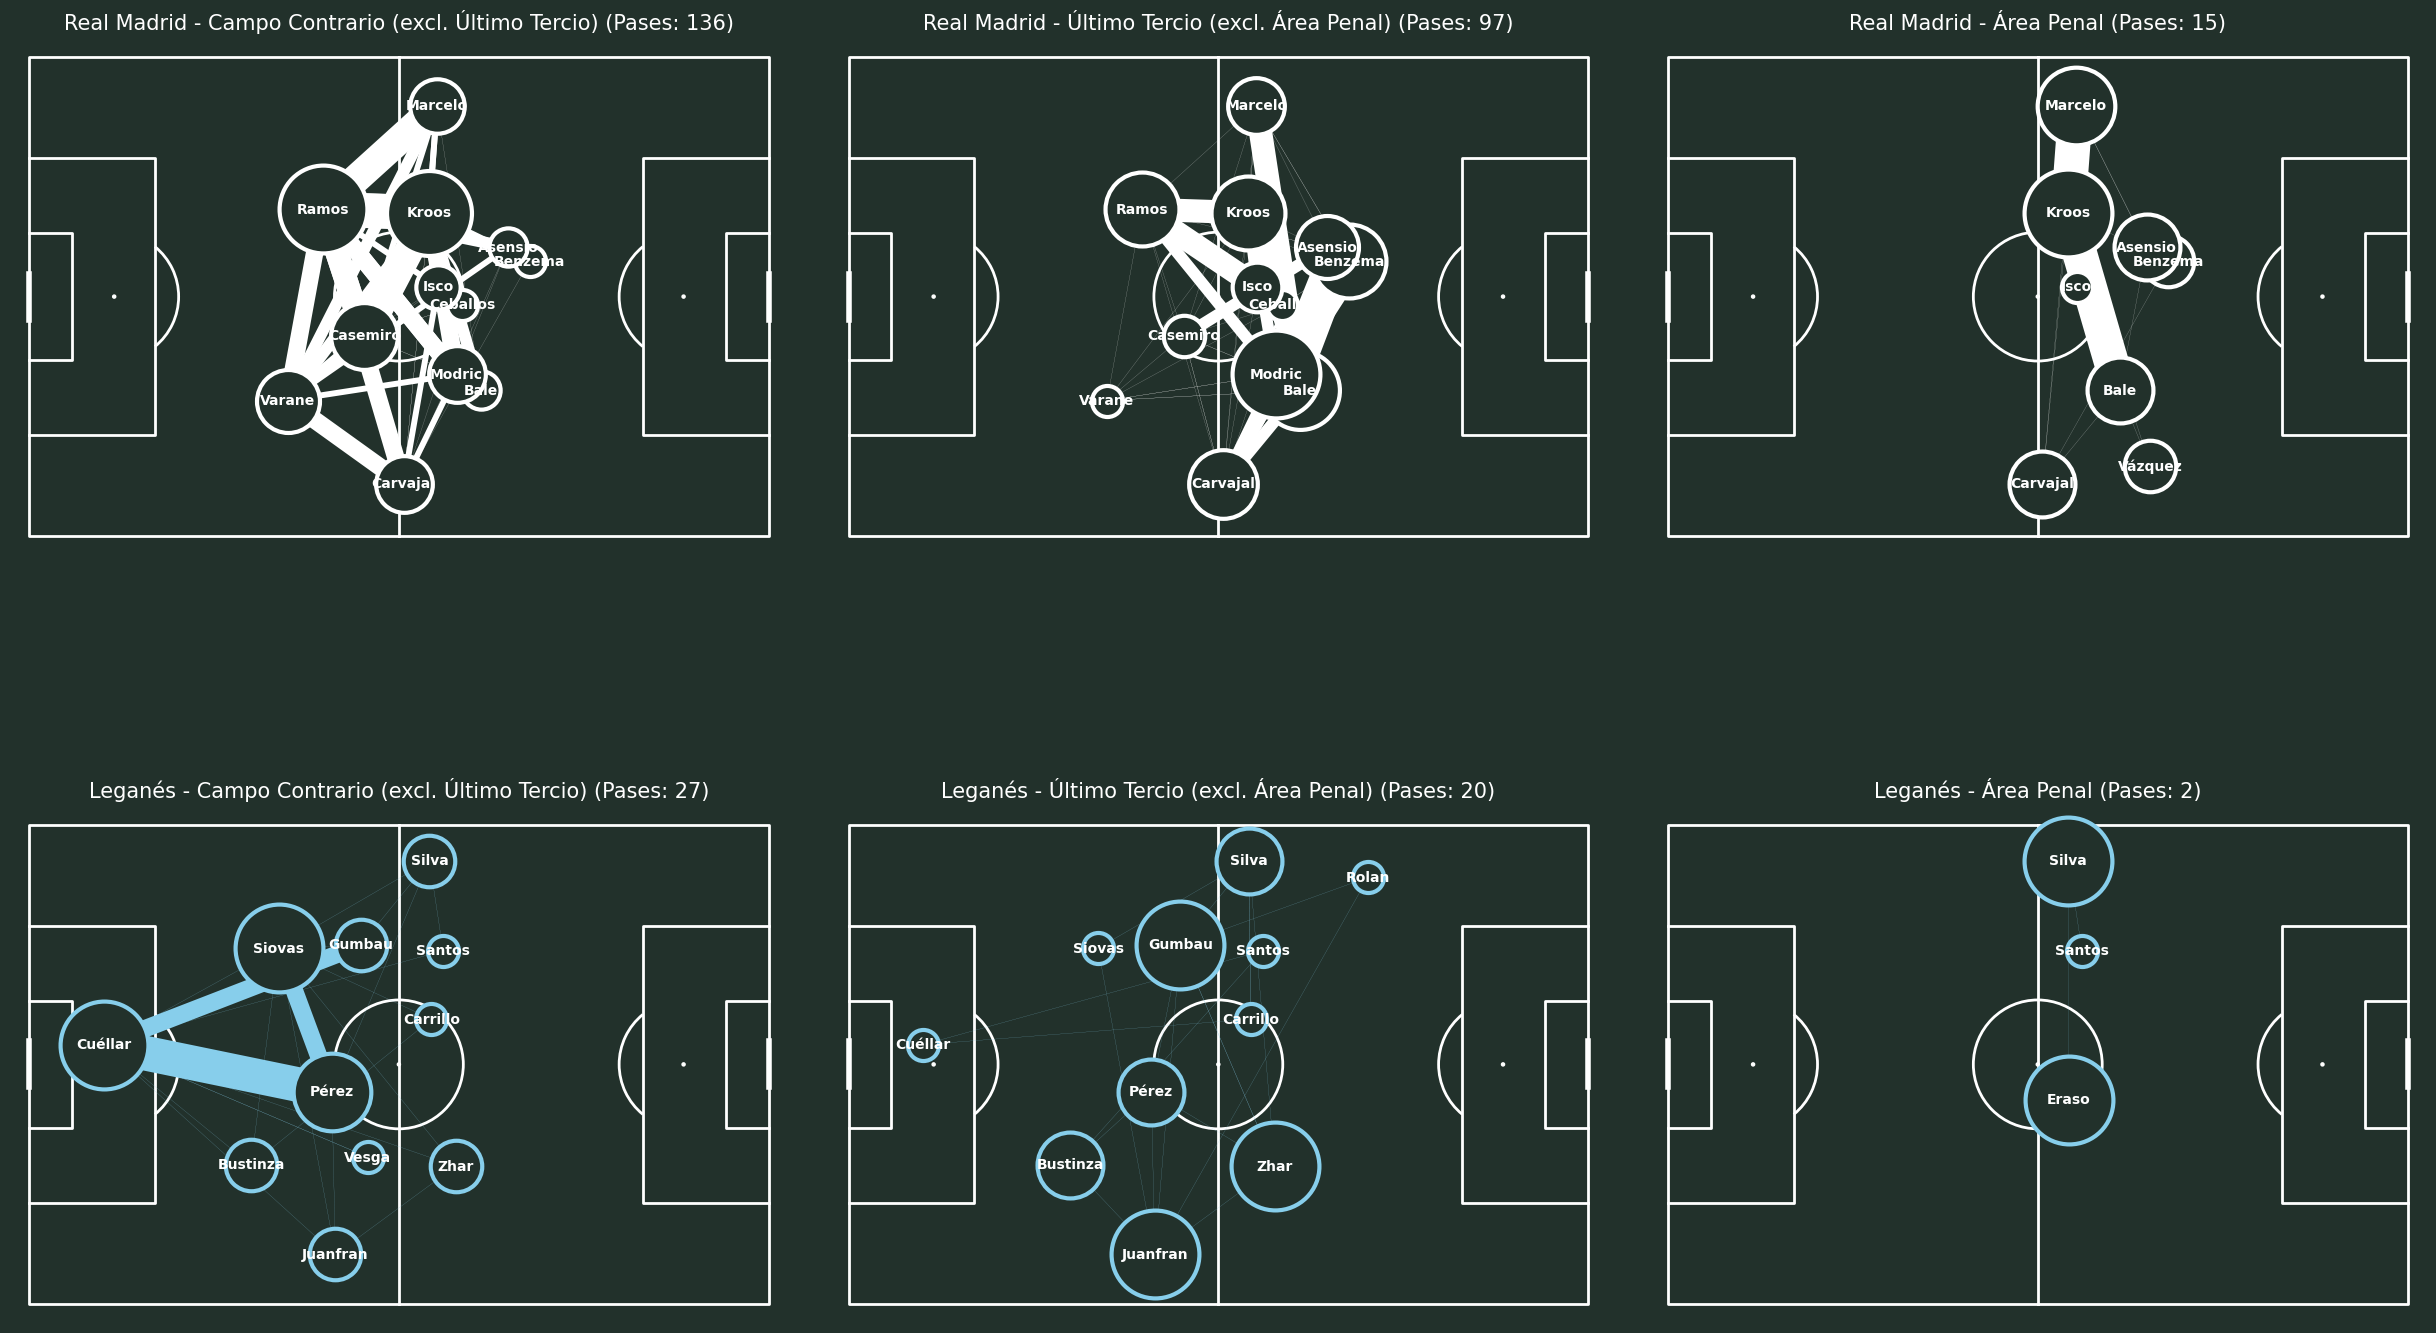

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from mplsoccer import Pitch

# --- 1. Definir constantes globales y límites de zonas ---
# NOTA: FIXED_NODE_SIZE ya no se usará directamente para el tamaño, pero se mantiene como referencia o valor por defecto
DEFAULT_NODE_SIZE = 2200 # Tamaño de nodo por defecto (si no hay pases dados u otro caso)
MIN_NODE_SIZE = 500 # Tamaño mínimo de nodo para escalado
MAX_NODE_SIZE = 4000 # Tamaño máximo de nodo para escalado

UNIFORM_LINE_ALPHA = 1.0 # Opacidad uniforme para las líneas de pase
MIN_PASS_LINEWIDTH = 0.1 # Grosor mínimo de la línea de pase (para 1 pase)
MAX_PASS_LINEWIDTH = 25 # Grosor máximo de la línea de pase

FINAL_THIRD_X = 66.6 # Límite X para el último tercio del campo
PENALTY_AREA_X = 83 # Límite X para el área penal

# --- 2. Funciones auxiliares para la preparación de datos ---

def inferir_conexiones_pases(df_pases_filtrados):
    """Identifica receptores y cuenta pases entre cada par de jugadores en un DataFrame filtrado."""
    df_sorted = df_pases_filtrados.sort_values(by=['period', 'min', 'sec']).reset_index(drop=True)

    df_sorted['recipient'] = df_sorted['player'].shift(-1)
    df_sorted['next_team'] = df_sorted['team'].shift(-1)
    df_sorted['next_period'] = df_sorted['period'].shift(-1)

    # Asigna un destinatario solo si el siguiente pase es del mismo equipo y en el mismo período
    df_sorted.loc[
        (df_sorted['team'] != df_sorted['next_team']) |
        (df_sorted['period'] != df_sorted['next_period']),
        'recipient'
    ] = None

    # Filtrar autopases y filas donde el destinatario es NaN
    pass_connections_data = df_sorted[
        (df_sorted['player'] != df_sorted['recipient']) &
        df_sorted['recipient'].notna()
    ].copy()

    # Agrupar por pasador y receptor para contar pases exitosos
    pass_connections = pass_connections_data.groupby(['player', 'recipient']).size().reset_index(name='num_passes')
    pass_connections = pass_connections.rename(columns={'player': 'passer'})
    return pass_connections

def calcular_posiciones_jugadores_filtrados(df_pases_filtrados):
    """Calcula la posición promedio de cada jugador basada en pases filtrados."""
    # Esta función ya no se usará directamente para las posiciones de los nodos
    # pero se mantiene si fuera necesaria para otras lógicas.
    return df_pases_filtrados.groupby('player')[['x', 'y']].mean().reset_index()

def preparar_datos_plot(pass_connections_df, player_positions_df):
    """Combina conexiones de pases con coordenadas de posiciones de jugadores."""
    plot_data = pass_connections_df.merge(
        player_positions_df.rename(columns={'x': 'x_start', 'y': 'y_start'}),
        left_on='passer',
        right_on='player',
        how='left'
    ).drop('player', axis=1)

    plot_data = plot_data.merge(
        player_positions_df.rename(columns={'x': 'x_end', 'y': 'y_end'}),
        left_on='recipient',
        right_on='player',
        how='left'
    ).drop('player', axis=1)
    return plot_data

# --- 3. Preparación de los datos para cada escenario y equipo ---

# Definir el filtro global: pases hacia delante O que finalizan en el área penal
# Se aplicará a todos los subplots.
is_forward_or_ends_in_penalty_rm = \
    (real_madrid_successful_passes['x_end'] > real_madrid_successful_passes['x']) | \
    (real_madrid_successful_passes['x_end'] > PENALTY_AREA_X)

is_forward_or_ends_in_penalty_le = \
    (leganes_successful_passes['x_end'] > leganes_successful_passes['x']) | \
    (leganes_successful_passes['x_end'] > PENALTY_AREA_X)

# --- 4. Objeto Pitch y figura con subplots ---

pitch = Pitch(pitch_type='opta', pitch_color='#22312b', line_color='white', stripe=False)

# Crear la figura y 6 subplots (2 filas, 3 columnas)
fig, axes = plt.subplots(2, 3, figsize=(25, 18))
fig.set_facecolor('#22312b') # Establecer el color de fondo de la figura para que coincida con el campo

# Aplanar los ejes para una fácil iteración
axes = axes.flatten()

# --- 5. Función auxiliar para trazar la red de pases por zona ---
def plot_pass_network_for_zone(ax, team_name, overall_player_positions_df, pass_plot_data, team_color, node_edge_color, label_type, title_suffix):
    pitch.draw(ax=ax)

    total_passes_in_subplot = pass_plot_data['num_passes'].sum() if not pass_plot_data.empty else 0
    ax.set_title(f'{team_name} - {title_suffix} (Pases: {total_passes_in_subplot})', color='white', fontsize=15)

    # Identificar jugadores que participan en esta red de pases específica (pasadores o receptores)
    participating_players_set = pd.concat([pass_plot_data['passer'], pass_plot_data['recipient']]).unique()

    # Filtrar las posiciones globales para incluir solo a los jugadores participantes
    player_nodes_to_plot = overall_player_positions_df[overall_player_positions_df['player'].isin(participating_players_set)].copy()

    # Calcular el total de pases dados por cada jugador en este subplot
    passes_given_by_player_in_subplot = pass_plot_data.groupby('passer')['num_passes'].sum().reset_index()
    passes_given_by_player_in_subplot.rename(columns={'passer': 'player', 'num_passes': 'total_passes_given'}, inplace=True)

    # Unir esta información con los nodos a graficar
    player_nodes_to_plot = player_nodes_to_plot.merge(passes_given_by_player_in_subplot, on='player', how='left')
    # Corrección del FutureWarning: reasignar el resultado de fillna
    player_nodes_to_plot['total_passes_given'] = player_nodes_to_plot['total_passes_given'].fillna(0) # Jugadores que solo reciben tendrán 0 pases dados

    # Determinar el rango de pases dados para el escalado de nodos en este subplot
    max_passes_given_in_subplot = player_nodes_to_plot['total_passes_given'].max()
    min_passes_given_in_subplot = player_nodes_to_plot['total_passes_given'].min()

    # Graficar nodos (posiciones promedio de los jugadores y etiquetas)
    for index, row in player_nodes_to_plot.iterrows():
        # Calcular el tamaño actual del nodo
        if max_passes_given_in_subplot == min_passes_given_in_subplot or max_passes_given_in_subplot == 0:
            current_node_size = MIN_NODE_SIZE # Si todos dan los mismos pases o ninguno, usar tamaño mínimo
        else:
            normalized_passes_given = (row['total_passes_given'] - min_passes_given_in_subplot) / (max_passes_given_in_subplot - min_passes_given_in_subplot)
            current_node_size = MIN_NODE_SIZE + normalized_passes_given * (MAX_NODE_SIZE - MIN_NODE_SIZE)

        pitch.scatter(
            row['x'], row['y'],
            ax=ax, s=current_node_size, # Usar tamaño de nodo dinámico
            color='#22312b', # El interior del nodo coincide con el fondo del campo
            edgecolors=node_edge_color, linewidth=3, alpha=UNIFORM_LINE_ALPHA, zorder=2
        )

        display_name = ''
        if label_type == 'last_name':
            # Mostrar solo el apellido si hay múltiples palabras, de lo contrario, el nombre completo
            display_name = row['player'].split(' ')[-1] if ' ' in row['player'] else row['player']
        elif label_type == 'initials':
            # Mostrar iniciales
            display_name = row['player'].split(' ')[-1] if ' ' in row['player'] else row['player']

        pitch.annotate(
            display_name, xy=(row['x'], row['y']),
            c='white', va='center', ha='center', size=10, weight='bold', ax=ax, zorder=3
        )

    # Calcular el número máximo y mínimo de pases para escalar el grosor de línea
    if not pass_plot_data.empty:
        max_num_passes = pass_plot_data['num_passes'].max()
        min_num_passes = pass_plot_data['num_passes'].min()
    else:
        max_num_passes = 1 # Valor predeterminado si no hay pases
        min_num_passes = 1 # Valor predeterminado si no hay pases

    # Graficar conexiones de pase (líneas)
    for index, row in pass_plot_data.iterrows():
        if max_num_passes == min_num_passes:
            current_linewidth = MIN_PASS_LINEWIDTH
        else:
            # Escalar el ancho de línea linealmente entre MIN_PASS_LINEWIDTH y MAX_PASS_LINEWIDTH
            normalized_passes = (row['num_passes'] - min_num_passes) / (max_num_passes - min_num_passes)
            current_linewidth = MIN_PASS_LINEWIDTH + normalized_passes * (MAX_PASS_LINEWIDTH - MIN_PASS_LINEWIDTH)

        pitch.lines(
            row['x_start'], row['y_start'],
            row['x_end'], row['y_end'],
            ax=ax, color=team_color,
            linewidth=current_linewidth,
            alpha=UNIFORM_LINE_ALPHA, zorder=1
        )


# --- 6. Configuración para cada subplot y llamada a la función auxiliar ---

# Real Madrid - Pases al campo contrario (excluyendo último tercio)
plot_pass_network_for_zone(
    ax=axes[0],
    team_name='Real Madrid',
    overall_player_positions_df=real_madrid_player_positions, # Posiciones generales de los jugadores del RM
    pass_plot_data=rm_opponent_half_plot_data,
    team_color='white',
    node_edge_color='white',
    label_type='last_name',
    title_suffix='Campo Contrario (excl. Último Tercio)'
)

# Real Madrid - Pases al último tercio (excluyendo área penal)
plot_pass_network_for_zone(
    ax=axes[1],
    team_name='Real Madrid',
    overall_player_positions_df=real_madrid_player_positions, # Posiciones generales de los jugadores del RM
    pass_plot_data=rm_final_third_plot_data,
    team_color='white',
    node_edge_color='white',
    label_type='last_name',
    title_suffix='Último Tercio (excl. Área Penal)'
)

# Real Madrid - Pases al área penal
plot_pass_network_for_zone(
    ax=axes[2],
    team_name='Real Madrid',
    overall_player_positions_df=real_madrid_player_positions, # Posiciones generales de los jugadores del RM
    pass_plot_data=rm_penalty_area_plot_data,
    team_color='white',
    node_edge_color='white',
    label_type='last_name',
    title_suffix='Área Penal'
)

# Leganés - Pases al campo contrario (excluyendo último tercio)
plot_pass_network_for_zone(
    ax=axes[3],
    team_name='Leganés',
    overall_player_positions_df=leganes_player_positions, # Posiciones generales de los jugadores del LE
    pass_plot_data=le_opponent_half_plot_data,
    team_color='skyblue',
    node_edge_color='skyblue',
    label_type='initials',
    title_suffix='Campo Contrario (excl. Último Tercio)'
)

# Leganés - Pases al último tercio (excluyendo área penal)
plot_pass_network_for_zone(
    ax=axes[4],
    team_name='Leganés',
    overall_player_positions_df=leganes_player_positions, # Posiciones generales de los jugadores del LE
    pass_plot_data=le_final_third_plot_data,
    team_color='skyblue',
    node_edge_color='skyblue',
    label_type='initials',
    title_suffix='Último Tercio (excl. Área Penal)'
)

# Leganés - Pases al área penal
plot_pass_network_for_zone(
    ax=axes[5],
    team_name='Leganés',
    overall_player_positions_df=leganes_player_positions, # Posiciones generales de los jugadores del LE
    pass_plot_data=le_penalty_area_plot_data,
    team_color='skyblue',
    node_edge_color='skyblue',
    label_type='initials',
    title_suffix='Área Penal'
)

# Ajustar el diseño y mostrar el gráfico
plt.tight_layout(pad=3.0) # Ajustar el relleno entre subplots
plt.show()